## Phase 3: Exploratory Data Analysis (EDA)

### Objective

The objective of Exploratory Data Analysis (EDA) is to understand the cleaned job market dataset by identifying patterns, trends, distributions, and relationships among different variables.

This phase focuses on analysing job postings based on country, job role, seniority level, work mode, experience, salary, education, skills, and posting dates.

Data visualisation is used to make the findings easier to understand and to identify meaningful insights from the dataset.

##  Required Libraries

- Pandas: Used for data manipulation and analysis.
- NumPy: Used for numerical operations.
- Matplotlib: Used for creating different visualizations.
- Seaborn: Used for statistical data visualization.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Set default chart size
plt.rcParams["figure.figsize"] = (10, 6)

# Display all columns
pd.set_option("display.max_columns", None)

##  Cleaned Dataset

The cleaned dataset is loaded into a Pandas DataFrame
for further exploratory analysis.

The original cleaned dataset is preserved, and all EDA
operations will be performed on the loaded DataFrame.

In [3]:
df = pd.read_csv("Cleaned_Job_Market_Dataset.csv")

# Display first five rows
df.head()

,posting_id,posted_date,title,company,role,seniority,category,city,region,country,Work Mode,experience_years,education,skills,salary_annual_usd,company_domain
0,0065c048923a,2026-01-01,Diagnostic Medical Sonographer,CCRM Fertility,healthcare,Unknown,Unknown,Austin,Texas,US,onsite,NaN,Unknown,Unknown,NaN,Unknown
1,008365bc7d00,2026-01-01,"Neurologist Movement Disorders | Renton, WA | ...",The Provider Finder,Unknown,Unknown,Unknown,Renton,Washington,US,onsite,NaN,Unknown,Unknown,NaN,Unknown
2,00b93252154b,2026-01-01,Entry-Level Public Projects Engineer - Rail,Olsson,Unknown,entry,Unknown,Omaha,Nebraska,US,onsite,NaN,Unknown,Unknown,NaN,Unknown
3,0115298b49e2,2026-01-01,Web Developer Job at Amicis Global in Scottsdale,Amicis Global,software-eng,Unknown,Unknown,Scottsdale,Arizona,US,onsite,NaN,Unknown,Unknown,NaN,Unknown
4,016ada42b5ed,2026-01-01,Health Service Specialist,Rosecrance Health Network,healthcare,Unknown,Unknown,Rockford,Illinois,US,onsite,NaN,Unknown,Unknown,NaN,Unknown


In [4]:

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null values
df.info()

# Display first five rows
display(df.head())

Dataset Shape: (100009, 16)

Column Names:
['posting_id', 'posted_date', 'title', 'company', 'role', 'seniority', 'category', 'city', 'region', 'country', 'Work Mode', 'experience_years', 'education', 'skills', 'salary_annual_usd', 'company_domain']
<class 'pandas.DataFrame'>
RangeIndex: 100009 entries, 0 to 100008
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   posting_id         100009 non-null  str    
 1   posted_date        100009 non-null  str    
 2   title              100009 non-null  str    
 3   company            100009 non-null  str    
 4   role               100009 non-null  str    
 5   seniority          100009 non-null  str    
 6   category           100009 non-null  str    
 7   city               100009 non-null  str    
 8   region             100009 non-null  str    
 9   country            100009 non-null  str    
 10  Work Mode          100009 non-null  str    
 11  experien

,posting_id,posted_date,title,company,role,seniority,category,city,region,country,Work Mode,experience_years,education,skills,salary_annual_usd,company_domain
0,0065c048923a,2026-01-01,Diagnostic Medical Sonographer,CCRM Fertility,healthcare,Unknown,Unknown,Austin,Texas,US,onsite,NaN,Unknown,Unknown,NaN,Unknown
1,008365bc7d00,2026-01-01,"Neurologist Movement Disorders | Renton, WA | ...",The Provider Finder,Unknown,Unknown,Unknown,Renton,Washington,US,onsite,NaN,Unknown,Unknown,NaN,Unknown
2,00b93252154b,2026-01-01,Entry-Level Public Projects Engineer - Rail,Olsson,Unknown,entry,Unknown,Omaha,Nebraska,US,onsite,NaN,Unknown,Unknown,NaN,Unknown
3,0115298b49e2,2026-01-01,Web Developer Job at Amicis Global in Scottsdale,Amicis Global,software-eng,Unknown,Unknown,Scottsdale,Arizona,US,onsite,NaN,Unknown,Unknown,NaN,Unknown
4,016ada42b5ed,2026-01-01,Health Service Specialist,Rosecrance Health Network,healthcare,Unknown,Unknown,Rockford,Illinois,US,onsite,NaN,Unknown,Unknown,NaN,Unknown


In [5]:
# Statistical summary of numerical columns
df.describe().T

,count,mean,std,min,25%,50%,75%,max
experience_years,21996.0,5.054328,3.639557,1.0,2.0,4.0,7.0,27.0
salary_annual_usd,14819.0,68278.445644,43353.353525,1200.0,37440.0,55000.0,90000.0,316800.0


In [9]:
df.describe(include=["object","str"]).T

,count,unique,top,freq
posting_id,100009,99162,66015a4eea46,4
posted_date,100009,181,2026-06-10,4650
title,100009,69808,Project Manager,285
company,100009,15922,Bank of America,868
role,100009,24,Unknown,27589
seniority,100009,9,Unknown,55464
category,100009,2052,Unknown,67203
city,100009,3083,Bengaluru,4740
region,100009,92,California,11867
country,100009,2,US,80015


### Analysis

Descriptive statistical analysis provides an overview
of the numerical and categorical variables.

The experience_years column helps us understand the
experience requirements mentioned in job postings.

The salary_annual_usd column provides information about
the annual salary ranges.

However, salary and experience statistics are calculated
only using available numerical values. Missing information
represented by Unknown or NaN is not treated as actual
salary or experience data.

# Job postings by country

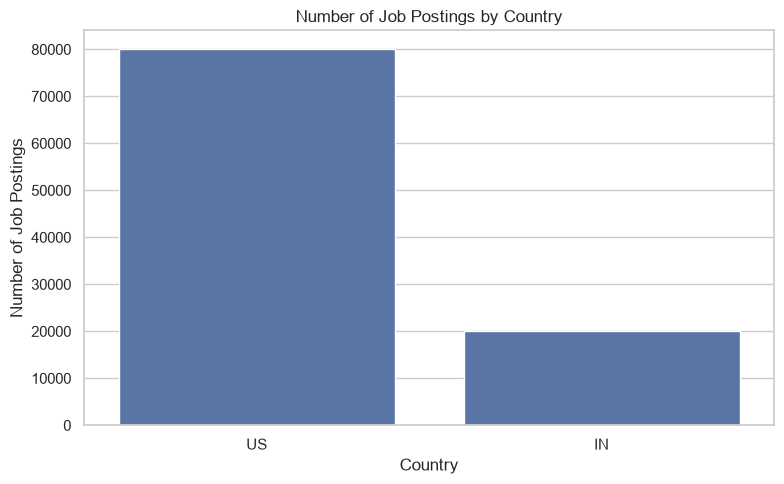

In [10]:
country_counts = df["country"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=country_counts.index,
    y=country_counts.values
)

plt.title("Number of Job Postings by Country")
plt.xlabel("Country")
plt.ylabel("Number of Job Postings")
plt.tight_layout()
plt.show()

### Analysis

The bar chart compares the number of job postings
between the United States and India.

The United States contributes 80,015 job postings,
while India contributes 19,994 job postings.

This indicates that the dataset contains a significantly
higher number of job opportunities from the United States.

Therefore, the dataset is more heavily represented by
US job postings than Indian job postings.

# Monthly job posting trends

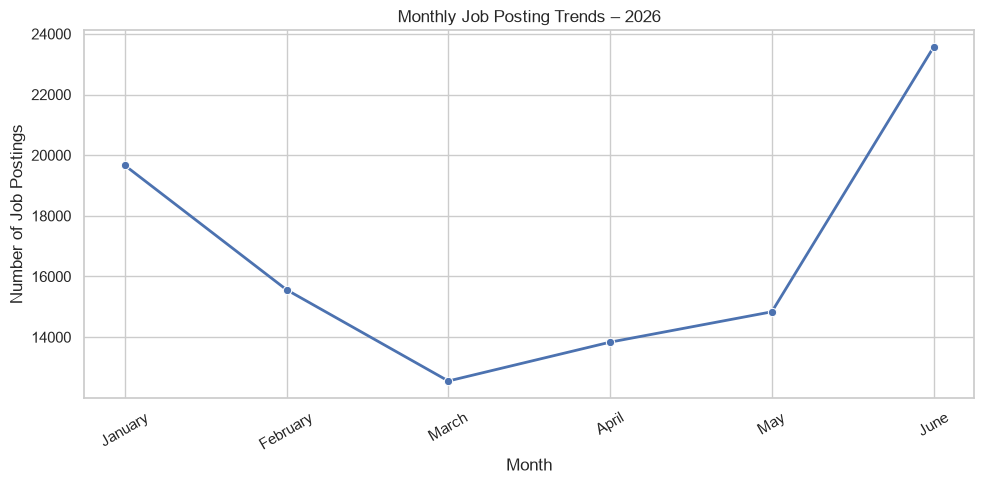

In [11]:
df["posted_date"] = pd.to_datetime(df["posted_date"])

monthly_jobs = (
    df.groupby(df["posted_date"].dt.month)
    .size()
)

month_names = {
    1: "January",
    2: "February",
    3: "March",
    4: "April",
    5: "May",
    6: "June"
}

monthly_jobs.index = monthly_jobs.index.map(month_names)

plt.figure(figsize=(10, 5))

sns.lineplot(
    x=monthly_jobs.index,
    y=monthly_jobs.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Job Posting Trends – 2026")
plt.xlabel("Month")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Analysis

The line chart represents the monthly distribution of
job postings from January to June 2026.

June recorded the highest number of job postings,
with 23,562 postings.

March recorded the lowest number, with 12,553 postings.

The number of postings declined from January to March,
followed by an increase from April to June.

This indicates a changing pattern in job posting activity
during the first half of 2026.

# Top 10 most common job roles

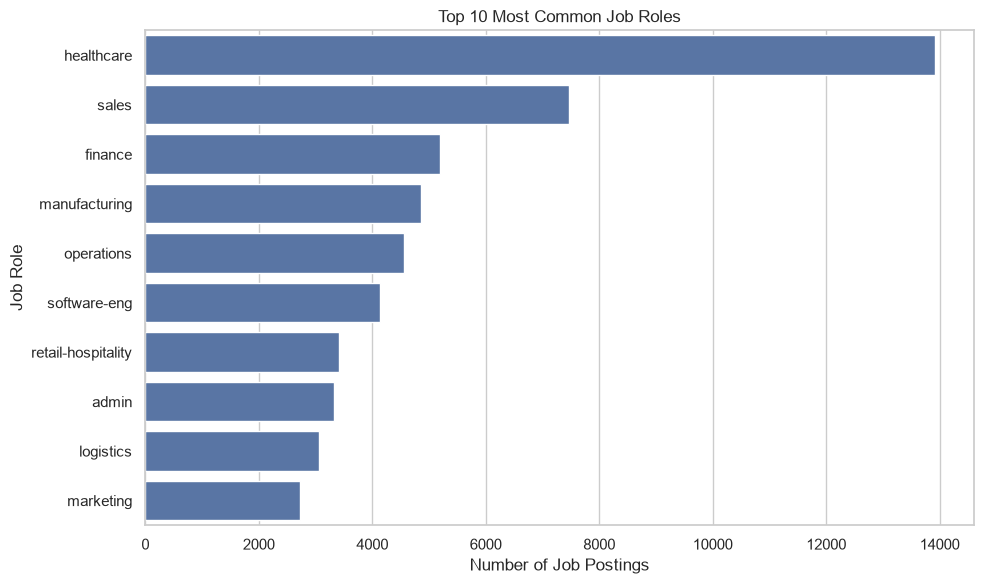

In [12]:
role_counts = (
    df[df["role"] != "Unknown"]["role"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=role_counts.values,
    y=role_counts.index
)

plt.title("Top 10 Most Common Job Roles")
plt.xlabel("Number of Job Postings")
plt.ylabel("Job Role")
plt.tight_layout()
plt.show()

### Analysis

The horizontal bar chart displays the top 10 job roles
based on their frequency in the dataset.

Healthcare is the most frequently appearing identified
job role, with 13,909 postings.

Sales follows with 7,468 postings, while Finance
accounts for 5,190 postings.

This indicates that Healthcare, Sales, and Finance
are prominent job categories in the available dataset.

Unknown job roles have been excluded from this chart
to focus on identified job roles.

# Job seniority distribution

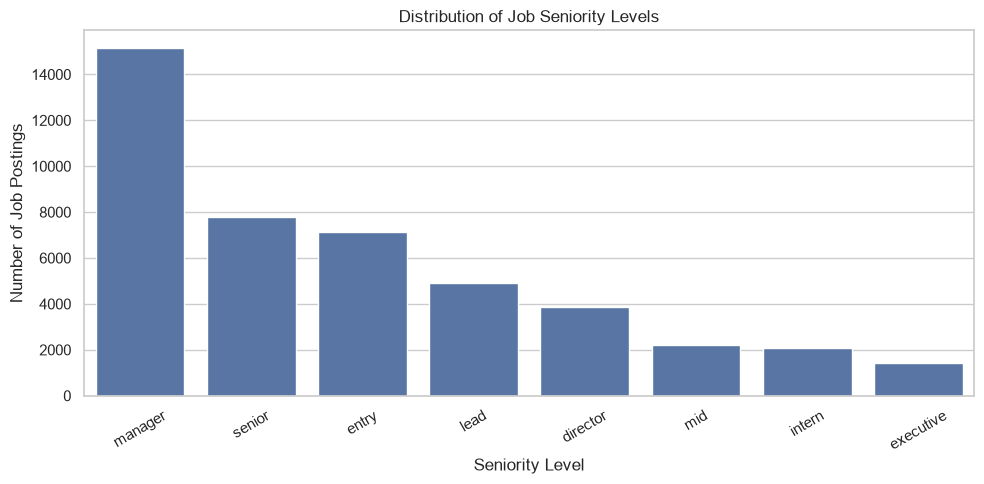

In [13]:
seniority_counts = (
    df[df["seniority"] != "Unknown"]["seniority"]
    .value_counts()
)

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df[df["seniority"] != "Unknown"],
    x="seniority",
    order=seniority_counts.index
)

plt.title("Distribution of Job Seniority Levels")
plt.xlabel("Seniority Level")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Analysis

The chart represents the distribution of different
seniority levels mentioned in job postings.

Manager-level positions are the most common identified
seniority category, with 15,156 postings.

Senior positions account for 7,777 postings,
followed by Entry-level positions with 7,136 postings.

This shows that the dataset includes opportunities
across different career levels, with Manager-level
positions appearing most frequently.

Unknown seniority values have been excluded
from this visualization.

# Work mode distribution

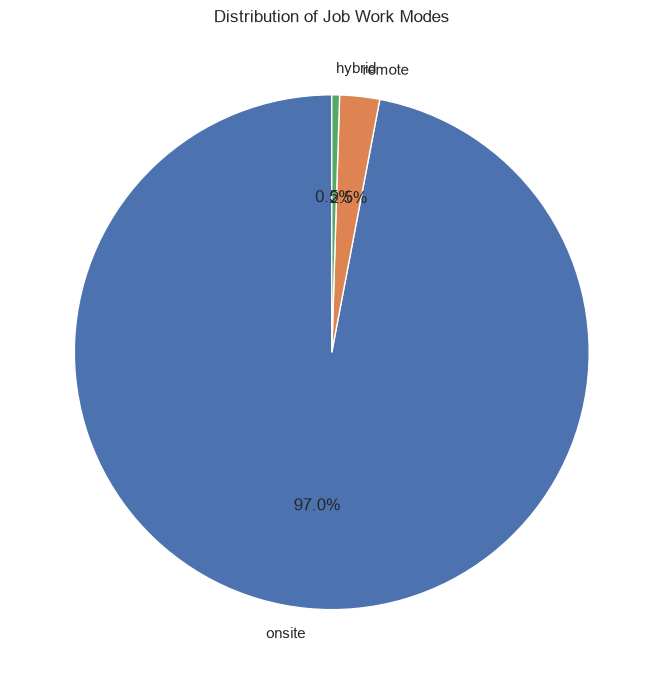

In [14]:
work_mode_counts = (
    df[df["Work Mode"] != "Unknown"]["Work Mode"]
    .value_counts()
)

plt.figure(figsize=(7, 7))

plt.pie(
    work_mode_counts.values,
    labels=work_mode_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Job Work Modes")
plt.tight_layout()
plt.show()

### Analysis

The pie chart illustrates the distribution of job
opportunities based on their work modes.

Among the postings with an identified work mode,
Onsite positions account for the largest share.

Remote opportunities account for a smaller proportion,
while Hybrid positions represent the smallest share.

A significant number of records have Unknown work modes.
Therefore, this chart represents only postings with
available work mode information.

The results indicate that onsite opportunities dominate
the identified work mode categories in this dataset.

# Most demanded skills

In [15]:
# Remove Unknown skill entries
skills_data = df.loc[
    df["skills"] != "Unknown", "skills"
].dropna()

# Split multiple skills into individual values
skills_data = skills_data.str.lower().str.split("|")

# Convert the list into individual rows
skills_data = skills_data.explode()

# Remove extra spaces
skills_data = skills_data.str.strip()

# Remove empty and Unknown values
skills_data = skills_data[
    (skills_data != "") &
    (skills_data != "unknown")
]

# Count individual skills
skill_counts = skills_data.value_counts().head(15)

display(skill_counts)

skills
python                  2394
excel                   1788
sql                     1727
aws                     1194
java                    1075
javascript               921
communication skills     815
project management       815
azure                    760
sales                    717
microsoft office         707
kubernetes               676
git                      675
data analysis            659
docker                   613
Name: count, dtype: int64

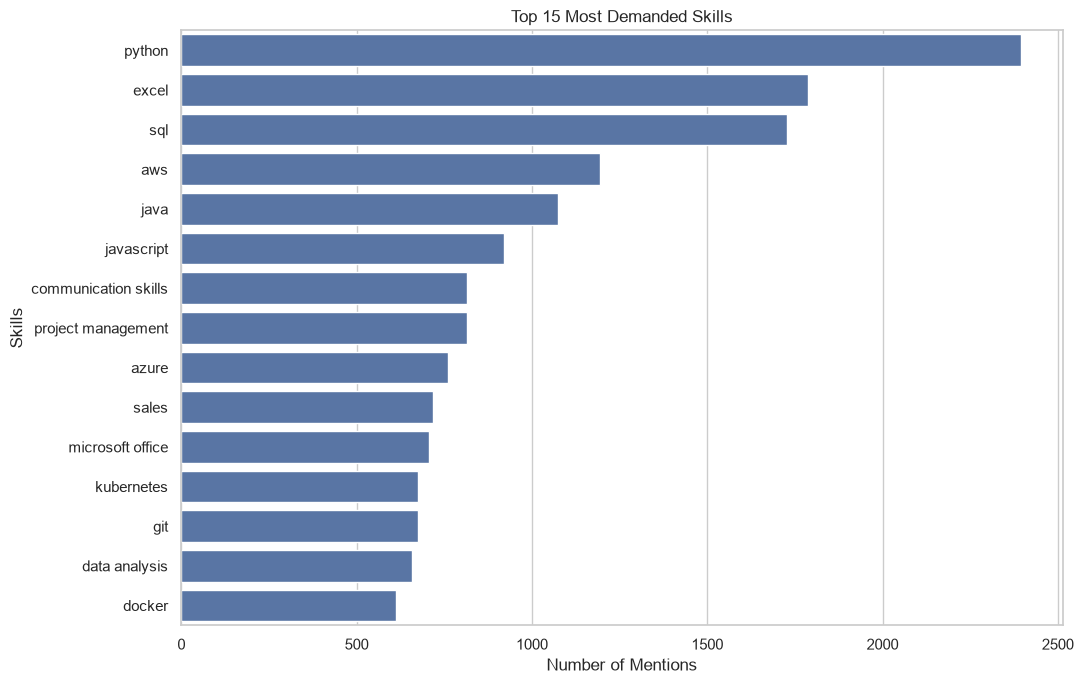

In [16]:
plt.figure(figsize=(11, 7))

sns.barplot(
    x=skill_counts.values,
    y=skill_counts.index
)

plt.title("Top 15 Most Demanded Skills")
plt.xlabel("Number of Mentions")
plt.ylabel("Skills")
plt.tight_layout()
plt.show()

### Analysis

The chart highlights the 15 most frequently mentioned
skills in the job postings.

Python is the most frequently mentioned skill,
with 2,394 mentions.

Excel follows with 1,788 mentions, while SQL accounts
for 1,727 mentions.

AWS, Java, and JavaScript are also among the frequently
mentioned technical skills.

Communication Skills and Project Management appear
among the important non-technical skills.

This indicates that employers mention a combination
of technical and soft skills in their job requirements.

Note: The counts represent individual skill mentions,
not the total number of unique job postings.

# Experience distribution

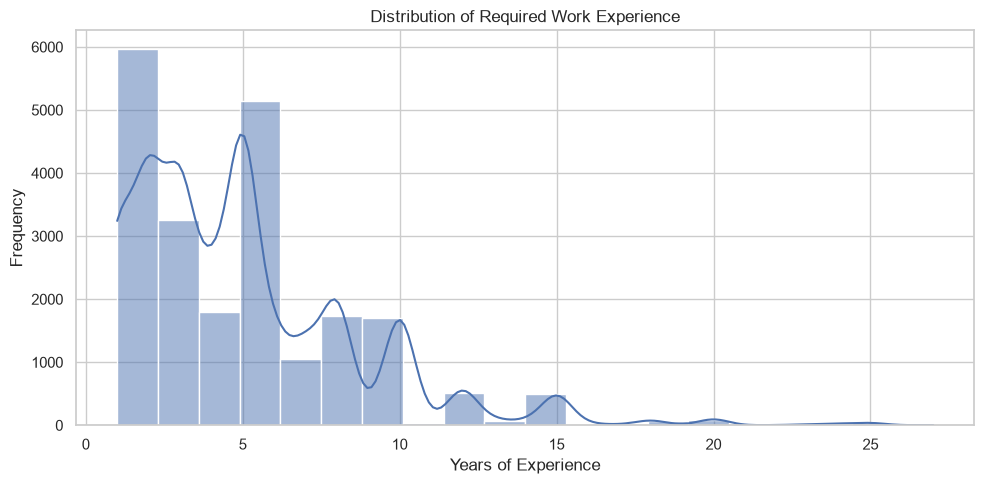

In [17]:
experience_data = df["experience_years"].dropna()

plt.figure(figsize=(10, 5))

sns.histplot(
    experience_data,
    bins=20,
    kde=True
)

plt.title("Distribution of Required Work Experience")
plt.xlabel("Years of Experience")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Analysis

The histogram shows the distribution of required
experience years across job postings.

The available experience values range from 1 to 27 years.

The mean experience requirement is approximately
5.05 years, while the median is 4 years.

The distribution helps us understand the experience
requirements across different job opportunities.

Only records containing available numerical experience
values are included in this analysis.

# Experience by seniority level

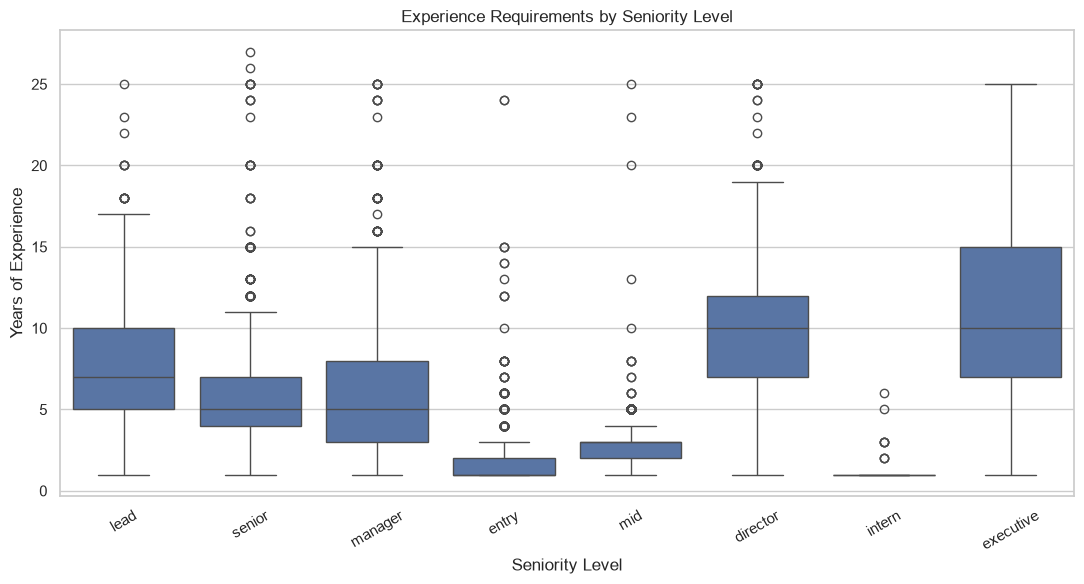

In [18]:
experience_seniority = df[
    (df["seniority"] != "Unknown") &
    (df["experience_years"].notna())
]

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=experience_seniority,
    x="seniority",
    y="experience_years"
)

plt.title("Experience Requirements by Seniority Level")
plt.xlabel("Seniority Level")
plt.ylabel("Years of Experience")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Analysis

The box plot compares experience requirements across
different seniority levels.

It displays the median, quartiles, and spread of
experience requirements for each seniority category.

This visualization helps identify whether senior,
managerial, entry-level, and other positions have
different experience expectations.

The box plot also helps identify unusually high
or low experience requirements.

Only available numerical experience values and
identified seniority levels are considered.

# Salary distribution

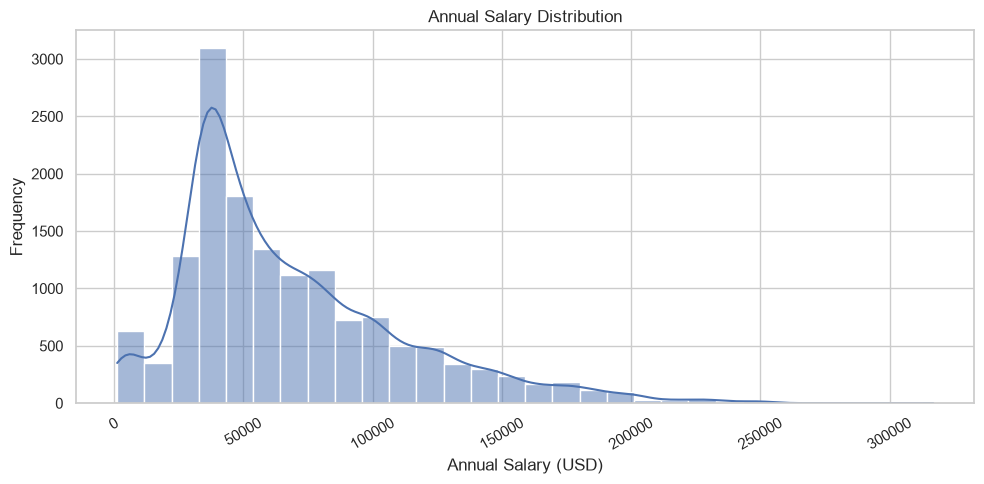

In [19]:
salary_data = df["salary_annual_usd"].dropna()

plt.figure(figsize=(10, 5))

sns.histplot(
    salary_data,
    bins=30,
    kde=True
)

plt.title("Annual Salary Distribution")
plt.xlabel("Annual Salary (USD)")
plt.ylabel("Frequency")
plt.ticklabel_format(style="plain", axis="x")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Analysis

The histogram illustrates the distribution of annual
salaries in USD.

The available salary values have a mean of approximately
$68,278, while the median salary is dollar 55,000.

The difference between the mean and median indicates
that some higher salary values influence the average.

The chart helps understand the salary distribution
and identify the concentration of salary values.

Only job postings with available salary information
are included in this analysis.

# Salary comparison by country

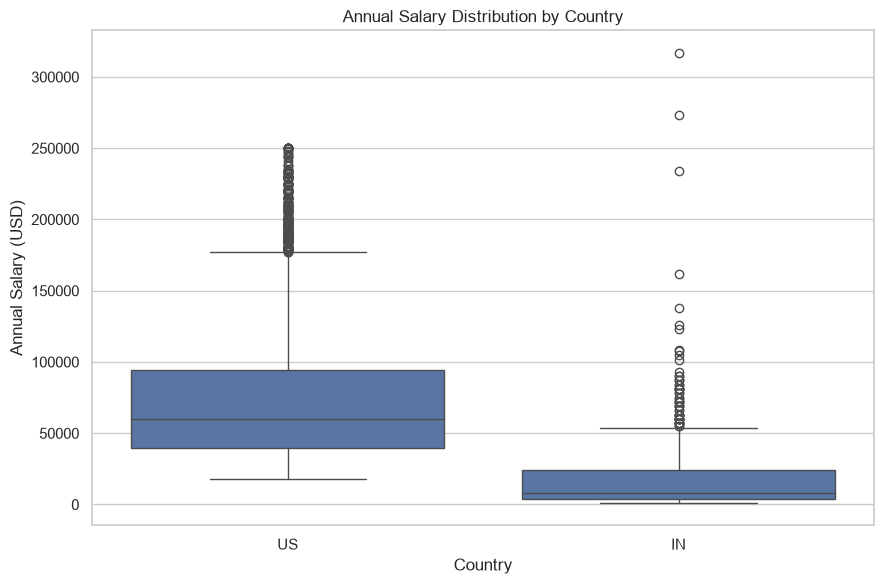

In [20]:
salary_country = df.dropna(
    subset=["salary_annual_usd", "country"]
)

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=salary_country,
    x="country",
    y="salary_annual_usd"
)

plt.title("Annual Salary Distribution by Country")
plt.xlabel("Country")
plt.ylabel("Annual Salary (USD)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

### Analysis

The box plot compares the annual salary distributions
of job postings from India and the United States.

The median salary for US postings is dollar 60,000,
while the median salary for Indian postings is $7,770.

This indicates a difference in the reported salary
distributions between the two countries.

However, salary comparisons should consider differences
in local labour markets and cost of living.

All salary values are expressed in USD.
Only postings with available salary information
are included.

# Average salary by job role

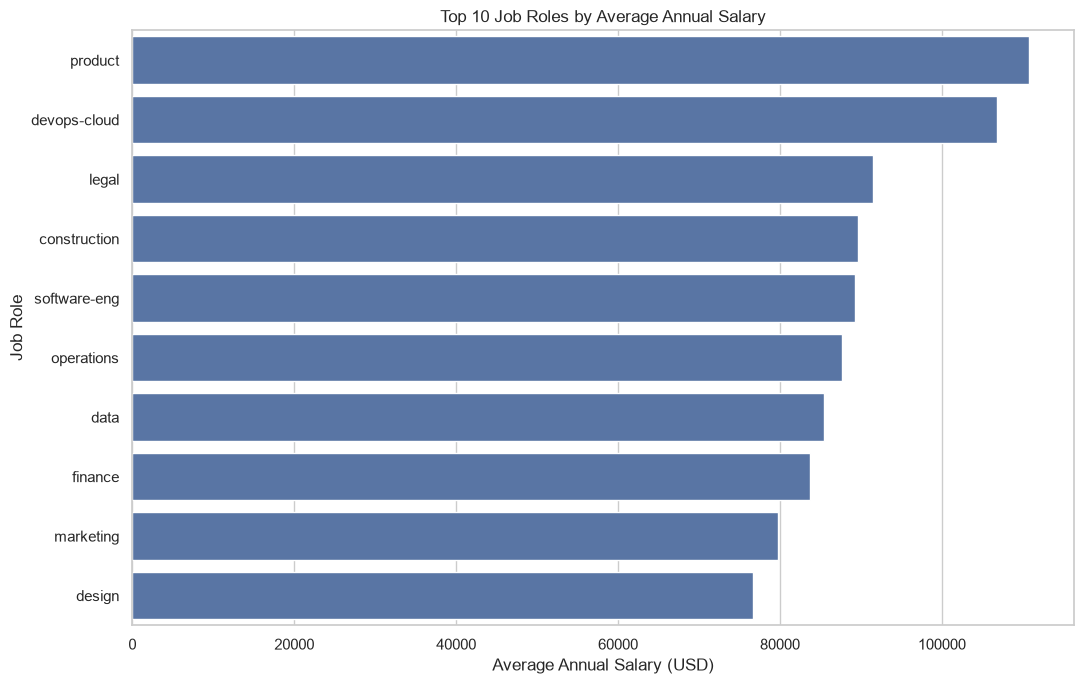

In [21]:
role_salary = (
    df[df["role"] != "Unknown"]
    .groupby("role")["salary_annual_usd"]
    .mean()
    .dropna()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(11, 7))

sns.barplot(
    x=role_salary.values,
    y=role_salary.index
)

plt.title("Top 10 Job Roles by Average Annual Salary")
plt.xlabel("Average Annual Salary (USD)")
plt.ylabel("Job Role")
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()
plt.show()

### Analysis

The chart compares the average annual salary across
the top 10 job roles with the highest average salaries.

It helps identify which job roles offer higher
reported annual compensation.

Salary information is not available for every job posting.
Therefore, the average salary is calculated using
only available salary records within each role.

The results should be interpreted alongside the number
of salary records available for each job role.

# Education qualification distribution

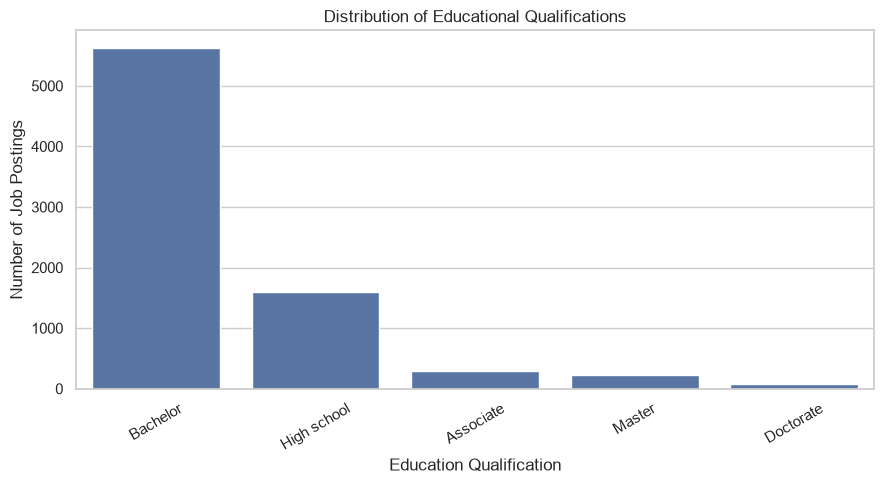

In [22]:
education_counts = (
    df[df["education"] != "Unknown"]["education"]
    .value_counts()
)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=education_counts.index,
    y=education_counts.values
)

plt.title("Distribution of Educational Qualifications")
plt.xlabel("Education Qualification")
plt.ylabel("Number of Job Postings")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### Analysis

The chart represents the educational qualifications
mentioned in the available job postings.

Bachelor's degree is the most frequently identified
educational qualification, followed by High School.

Associate, Master's, and Doctorate qualifications
also appear in the dataset.

However, most records have Unknown education information.
Therefore, the chart represents only postings with
identified educational qualifications.

This analysis helps understand the educational
requirements mentioned by employers.

# Correlation analysis

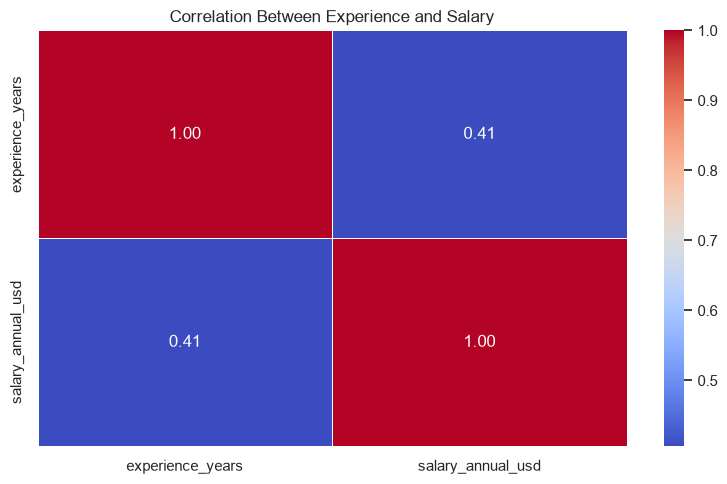

In [23]:
numerical_data = df[
    ["experience_years", "salary_annual_usd"]
]

correlation_matrix = numerical_data.corr()

plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Experience and Salary")
plt.tight_layout()
plt.show()

### Analysis

The correlation heatmap represents the relationship
between experience years and annual salary.

The correlation coefficient ranges from -1 to +1.

- +1 indicates a perfect positive relationship.
- -1 indicates a perfect negative relationship.
- 0 indicates no linear relationship.

The heatmap helps us understand whether higher
experience requirements are associated with
higher annual salaries.

Correlation does not necessarily indicate causation.

The calculation uses records where both numerical
variables are available.

# Experience vs salary

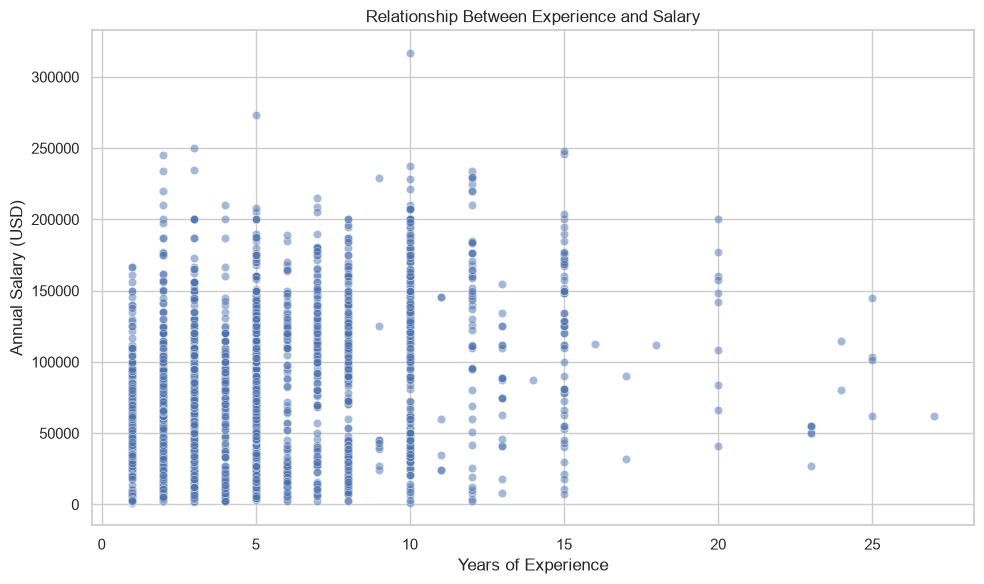

In [24]:
experience_salary = df.dropna(
    subset=["experience_years", "salary_annual_usd"]
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=experience_salary,
    x="experience_years",
    y="salary_annual_usd",
    alpha=0.5
)

plt.title("Relationship Between Experience and Salary")
plt.xlabel("Years of Experience")
plt.ylabel("Annual Salary (USD)")
plt.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

### Analysis

The scatter plot illustrates the relationship between
required years of experience and annual salary.

Each point represents a job posting containing
both experience and salary information.

This visualization helps identify whether salary
generally increases with experience.

It also helps identify unusual salary values
and variations in salary at similar experience levels.

The relationship should be interpreted carefully
because salary is also influenced by job role,
location, industry, and seniority.

# Final EDA findings

# Key Findings from Exploratory Data Analysis

The Exploratory Data Analysis provided several insights
into the job market dataset.

1. Country Distribution:
   The United States contributes the highest number
   of job postings, compared with India.

2. Monthly Trends:
   June recorded the highest number of job postings,
   while March recorded the lowest.

3. Job Roles:
   Healthcare, Sales, and Finance are among the
   most frequently identified job roles.

4. Skill Demand:
   Python, Excel, and SQL are among the most frequently
   mentioned skills.

5. Work Mode:
   Onsite opportunities dominate the identified
   work mode categories.

6. Experience:
   The median required experience is 4 years,
   based on available numerical records.

7. Salary:
   The median reported annual salary is $55,000
   across available salary records.

8. Education:
   Bachelor's degree is the most frequently identified
   educational qualification.

9. Experience and Salary:
   The correlation analysis helps examine the
   relationship between experience and salary.

Overall, the analysis provides an understanding of
job market patterns, skill requirements, salary
distributions, and employment trends.